# 4.01 · Data drift y pérdida de performance del champion

**Proyecto:** MiBici · TC5044.10 · Equipo 04
**Autor:** José Eduardo De Moraes López
**Componente:** Data drift y performance drift (Entrega Final)
**Rama:** `feat/final-drift` · **Contrato:** `docs/final/drift_contract.md`
**Fecha:** 20 de noviembre de 2026

## 0. Objetivo

Mostrar que el equipo puede detectar dos problemas distintos del modelo en producción:

| Concepto | Pregunta | ¿Necesita las salidas observadas? |
|---|---|---|
| **Data drift** | ¿Las entradas del modelo se ven distintas? | No: se mide el mismo día |
| **Performance drift** | ¿El modelo se equivoca más? (WAPE, MAE) | Sí |

Detectar data drift no prueba que el modelo empeore, y el modelo puede empeorar sin data drift. Por eso esta libreta los reporta por separado.

**Qué hace esta libreta.** Solo **lee, valida y explica**. Toda la lógica vive en `mibici/monitoring/` y tiene pruebas en `tests/test_drift.py`:

- `drift.py`: PSI, KS y las cuatro reglas de alerta.
- `scenarios.py`: calibración y construcción de los escenarios S1 a S4.
- `evaluation.py`: corre todo y escribe la evidencia con `make drift`.

Las tablas que se leen aquí son las de `reports/evidence/final_drift/`.

## 1. Configuración

In [1]:
import json

from IPython.display import Image, display
import numpy as np
import pandas as pd

from mibici.config import CHAMPION_EXPORT_DIR, FEATURES
from mibici.modeling.train import load_modeling_table
from mibici.monitoring import scenarios as sc
from mibici.monitoring.drift import ALARM_EXCLUDED, PSI_MODERATE, PSI_STRONG, quantile_edges
from mibici.monitoring.evaluation import DRIFT_EVIDENCE_DIR

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
EVIDENCE = DRIFT_EVIDENCE_DIR
print("Evidencia:", EVIDENCE)
print("Referencia:", sc.REFERENCE_PERIOD, "· Actual:", sc.CURRENT_PERIOD)

2026-11-20 20:25:04.066 -06:00 | INFO     | mibici.config:<module>:12 - PROJ_ROOT path is: C:\Users\lalo4\MiBici


Evidencia: C:\Users\lalo4\MiBici\reports\evidence\final_drift
Referencia: ('2026-06-01', '2026-08-01') · Actual: ('2026-08-01', '2026-10-01')


## 2. Datos, periodos y evidencia

| Rol | Periodo | Por qué |
|---|---|---|
| Referencia de data drift | 1 jun – 31 jul 2026 | Últimos datos que vio el champion (versión 3, entrenada hasta el 31 de julio) |
| Actual (natural) | 1 ago – 30 sep 2026 | El periodo de "producción". Su WAPE (0.6066) es la referencia de desempeño |
| Control | Muestra bootstrap de la referencia | No debe levantar ninguna alarma |

Junio y julio **solo** sirven como referencia de las distribuciones: el champion se entrenó con esos meses, así que su error ahí no mide nada. La celda siguiente carga la tabla de modelado, que es la misma de la Fase 2 (`processed_v1` con `add_history_features`), y lee la evidencia que escribió `make drift`.

In [18]:
df = load_modeling_table()
reference = sc.period_rows(df, sc.REFERENCE_PERIOD)
current = sc.period_rows(df, sc.CURRENT_PERIOD)
print(f"Tabla completa: {len(df):,} filas")
print(f"Referencia: {len(reference):,} filas · {reference['station_id'].nunique()} estaciones")
print(f"Actual:     {len(current):,} filas · {current['station_id'].nunique()} estaciones")

drift = pd.read_csv(EVIDENCE / "drift_by_feature.csv")
performance = pd.read_csv(EVIDENCE / "performance_by_segment.csv")
alerts = pd.read_csv(EVIDENCE / "alerts.csv")
calibration = pd.read_csv(EVIDENCE / "calibration.csv")
run_info = json.loads((EVIDENCE / "run_info.json").read_text(encoding="utf-8"))
run_info

Tabla completa: 11,949,160 filas
Referencia: 511,960 filas · 454 estaciones
Actual:     568,140 filas · 469 estaciones


{'git_commit': '7880446b8addcd162b460578056806543820c4d9',
 'git_branch': 'feat/final-drift',
 'git_dirty': 'false',
 'model': 'models\\serving\\champion',
 'reference_period': ['2026-06-01', '2026-08-01'],
 'current_period': ['2026-08-01', '2026-10-01'],
 'random_state': 0}

**Validación de la evidencia.** Se revisan cuatro cosas antes de interpretar nada:

1. La evidencia salió de un commit limpio (`git_dirty = false`).
2. El periodo natural reproduce las cifras oficiales de la Fase 2 en test: champion 0.6066 y baseline 0.6227.
3. El control no levanta ninguna alarma.
4. Están los 12 escenarios (4 × 3 niveles), además del control y el periodo natural.

In [19]:
natural_all = performance.query("scenario == 'natural' and segment == 'all'").set_index("model")
checks = {
    "commit limpio": run_info["git_dirty"] == "false",
    "champion natural = 0.6066": round(natural_all.loc["champion", "wape"], 4) == 0.6066,
    "baseline natural = 0.6227": round(natural_all.loc["baseline", "wape"], 4) == 0.6227,
    "control sin alarmas": alerts.query("scenario == 'control'")["action"].eq("none").all(),
    "control: todo PSI < 0.1": drift.query("scenario == 'control'")["psi"].lt(PSI_MODERATE).all(),
    "14 casos": len(alerts) == 14,
}
assert all(checks.values()), checks
pd.Series(checks, name="ok")

commit limpio                True
champion natural = 0.6066    True
baseline natural = 0.6227    True
control sin alarmas          True
control: todo PSI < 0.1      True
14 casos                     True
Name: ok, dtype: bool

## 3. Qué variables cuentan para la alarma de data drift

El contrato monitorea las siete variables y la predicción. Usa PSI con 10 bins por cuantiles de la referencia (o por categoría) y el estadístico D de KS para las numéricas. Antes de ver los escenarios, conviene ver el **periodo natural**: agosto–septiembre comparado con junio–julio, sin perturbar nada.

In [4]:
natural_drift = drift.query("scenario == 'natural'").drop(columns=["scenario", "level"])
natural_drift.round(4)

,feature,kind,psi,ks_d,status,alarm
8,hour,categorical,0.0000,NaN,stable,True
9,day_of_week,categorical,0.0079,NaN,stable,True
10,is_weekend,categorical,0.0052,NaN,stable,True
11,month,categorical,17.0329,NaN,strong,False
12,station_age_days,numeric,1.4453,0.1872,strong,False
13,avg_4_weeks,numeric,0.0036,0.0281,stable,True
14,t_168,numeric,0.0002,0.0130,stable,True
15,prediction,numeric,0.0044,0.0290,stable,True


Dos variables salen con drift fuerte aunque no cambió nada en los datos:

- **`month`** (PSI ≈ 17): junio–julio y agosto–septiembre no comparten ningún mes. El contrato ya la excluye de las alarmas.
- **`station_age_days`** (PSI ≈ 1.45, KS D = 0.19): en el periodo actual cada estación tiene dos meses más de antigüedad, y las 98 estaciones de la cohorte 2026 pasan de tener 0–60 días a tener 60–120.

Las dos crecen con el calendario, así que **cualquier periodo posterior siempre va a tener drift**. Si `station_age_days` contara para la alarma, la alarma sonaría siempre, también en el periodo natural, y no distinguiría nada. Por eso se reporta pero **no se alarma** (`ALARM_EXCLUDED`). Este es un **ajuste al contrato** que se propone al equipo en el PR. Las demás variables y la predicción quedan con PSI < 0.01 en el periodo natural.

In [5]:
print("Excluidas de la alarma:", ALARM_EXCLUDED)
age = pd.DataFrame({
    "referencia": reference["station_age_days"].describe(percentiles=[0.1, 0.5, 0.9]),
    "actual": current["station_age_days"].describe(percentiles=[0.1, 0.5, 0.9]),
}).T[["10%", "50%", "90%"]]
age

Excluidas de la alarma: ('month', 'station_age_days')


,10%,50%,90%
referencia,39.0,3582.0,4230.0
actual,62.0,2872.0,4288.0


## 4. Calibración de los escenarios con datos reales

Ninguna magnitud se escribió a mano: `scenarios.calibrate` las calcula de `processed_v1`. Las celdas de esta sección repiten cada cálculo paso a paso y comprueban que da lo mismo que `calibration.csv`.

### 4.1 S1 · Cambio de demanda: variación anual de las salidas mensuales

S1 multiplica las salidas desde el 1 de agosto por un factor y **recalcula** `avg_4_weeks` y `t_168` con `add_history_features`. El factor sale del cambio anual observado: las salidas de cada mes contra las del mismo mes del año anterior.

In [6]:
yoy = sc.year_over_year_change(df)
print(yoy.round(3).tail(12).to_string())
q = yoy.abs().quantile([0.5, 0.9, 1.0])
s1 = pd.DataFrame({"cuantil de |cambio anual|": q.values, "factor": 1 + q.values},
                  index=["mild (mediana)", "moderate (p90)", "strong (máximo)"])
s1

hour_start
2025-10   -0.005
2025-11   -0.028
2025-12   -0.014
2026-01   -0.065
2026-02   -0.122
2026-03   -0.075
2026-04   -0.043
2026-05   -0.209
2026-06   -0.024
2026-07    0.038
2026-08    0.034
2026-09    0.284
Freq: M


,cuantil de |cambio anual|,factor
mild (mediana),0.042796,1.042796
moderate (p90),0.136108,1.136108
strong (máximo),0.284175,1.284175


De 2023 a 2026, la mediana del cambio anual (en valor absoluto) es 4.3 %, el percentil 90 es 13.6 % y el máximo es **+28.4 %**, que corresponde a septiembre de 2026. Por eso el cambio se simula como **aumento**: el cambio más grande que se ha observado fue de crecimiento.

### 4.2 S2 · Expansión de estaciones: crecimiento de la cohorte 2026

S2 vuelve a muestrear las filas del periodo actual para subir la proporción de filas de la cohorte de estaciones nuevas. Cada nivel parte de la proporción actual y le suma 1, 3 o 6 meses más de crecimiento al ritmo que se observó.

In [7]:
share = sc.cohort_share_by_month(df)
growing = share[share > 0]
pace = (growing.iloc[-1] - growing.iloc[0]) / (len(growing) - 1)
current_share = current["is_new_station_cohort"].mean()
print(growing.round(4).to_string())
print(f"\nRitmo: {pace:.4f} por mes · proporción actual: {current_share:.4f}")
pd.Series({lvl: current_share + m * pace for lvl, m in sc.EXPANSION_MONTHS.items()},
          name="proporción de la cohorte")

hour_start
2026-05    0.0038
2026-06    0.0808
2026-07    0.1604
2026-08    0.2042
2026-09    0.2093
Freq: M

Ritmo: 0.0514 por mes · proporción actual: 0.2067


mild        0.258092
moderate    0.360857
strong      0.515004
Name: proporción de la cohorte, dtype: float64

La cohorte pasó de 0.4 % de las filas en mayo a 20.9 % en septiembre, unos **5.1 puntos por mes**. Los niveles quedan en 25.8 %, 36.1 % y 51.5 % de las filas. Al volver a muestrear se conservan todas las filas de la cohorte, se duplican las que faltan y el resto se toma sin reemplazo, de modo que el total de filas no cambia.

### 4.3 S3 · Falla de datos: `t_168` llega en 0

S3 pone `t_168 = 0` en todas las filas de una parte de las estaciones. Solo cambian las variables. Los niveles van de una estación a un grupo grande:

- **mild:** 1 estación (una falla aislada).
- **moderate:** tantas estaciones como la cohorte 2026, 98 de 469 (20.9 %). Es el grupo más grande que la red agregó de una vez, y podría tener su propio flujo de datos.
- **strong:** las 469 estaciones (falla completa del flujo).

In [8]:
stations = current["station_id"].nunique()
cohort = current.loc[current["is_new_station_cohort"], "station_id"].nunique()
pd.Series({"mild": 1 / stations, "moderate": cohort / stations, "strong": 1.0},
          name="proporción de estaciones")

mild        0.002132
moderate    0.208955
strong      1.000000
Name: proporción de estaciones, dtype: float64

### 4.4 S4 · Cambio de concepto: la caída de los días extraordinarios

S4 baja las salidas observadas en algunas horas y deja las variables **igual**. Simula que cambió la relación entre las entradas y la demanda. La magnitud sale de los dos días con evento extraordinario de los datos (22 y 23 de febrero de 2026): para cada hora se divide la suma de salidas observadas entre la suma de `avg_4_weeks`, que es lo que la historia esperaba.

In [9]:
ratios = sc.event_hour_ratios(df)
events = df[df["is_extraordinary_event"]]
daily = events["departures"].sum() / events["avg_4_weeks"].sum()
hours = sc.concept_hours(ratios, daily)
print(f"Días de evento: {sorted(events['hour_start'].dt.date.unique())}")
print(f"Observado / esperado en todo el día: {daily:.3f}")
print(f"Horas seleccionadas (caída mayor que la del día): {hours}")
ratios.rename("observado / esperado").round(3).to_frame().T

Días de evento: [datetime.date(2026, 2, 22), datetime.date(2026, 2, 23)]
Observado / esperado en todo el día: 0.264
Horas seleccionadas (caída mayor que la del día): [11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]


hour,0,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
observado / esperado,0.556,0.759,0.454,0.438,0.519,0.692,0.477,0.167,0.201,0.169,0.202,0.187,0.155,0.168,0.164,0.173,0.141,0.14,0.092,0.075


Esos días salió solo el **26 %** de lo esperado. La caída fue mucho mayor de las 11:00 en adelante (entre 7 % y 20 % de lo esperado) que en la mañana (44 %–76 %). Se seleccionan las horas en las que la caída fue **mayor que la del día completo**: de 11:00 a 23:00. En cada hora seleccionada el factor es `1 − fracción × (1 − razón de esa hora)`, con fracción 0.25 (mild), 0.5 (moderate) o 1 (strong, la caída completa del evento). En promedio, los factores quedan en 0.79, 0.58 y 0.16.

In [10]:
recomputed = sc.calibrate(df)
saved = calibration.copy()
for scenario, levels in recomputed.items():
    for level, value in levels.items():
        rows = saved[(saved["scenario"] == scenario) & (saved["level"] == level)]
        expected = list(value.values()) if isinstance(value, dict) else [value]
        np.testing.assert_allclose(rows["magnitude"].to_numpy(), expected)
print("calibration.csv coincide con scenarios.calibrate(df)")
alerts[["scenario", "level", "magnitude", "description"]]

calibration.csv coincide con scenarios.calibrate(df)


,scenario,level,magnitude,description
0,control,none,NaN,bootstrap sample of the reference
1,natural,none,NaN,current period without changes
2,S1_demand_shift,mild,1.042796,"departures x 1.043 from 2026-08-01, features r..."
3,S1_demand_shift,moderate,1.136108,"departures x 1.136 from 2026-08-01, features r..."
4,S1_demand_shift,strong,1.284175,"departures x 1.284 from 2026-08-01, features r..."
5,S2_station_expansion,mild,0.258092,new-station cohort = 25.8% of the rows
6,S2_station_expansion,moderate,0.360857,new-station cohort = 36.1% of the rows
7,S2_station_expansion,strong,0.515004,new-station cohort = 51.5% of the rows
8,S3_data_failure,mild,0.002132,t_168 = 0 for 0.2% of the stations
9,S3_data_failure,moderate,0.208955,t_168 = 0 for 20.9% of the stations


## 5. Data drift por escenario

La figura 4.01a muestra el PSI de cada variable en cada escenario y nivel. `month` y `station_age_days` aparecen como referencia, pero no cuentan para la alarma (sección 3).

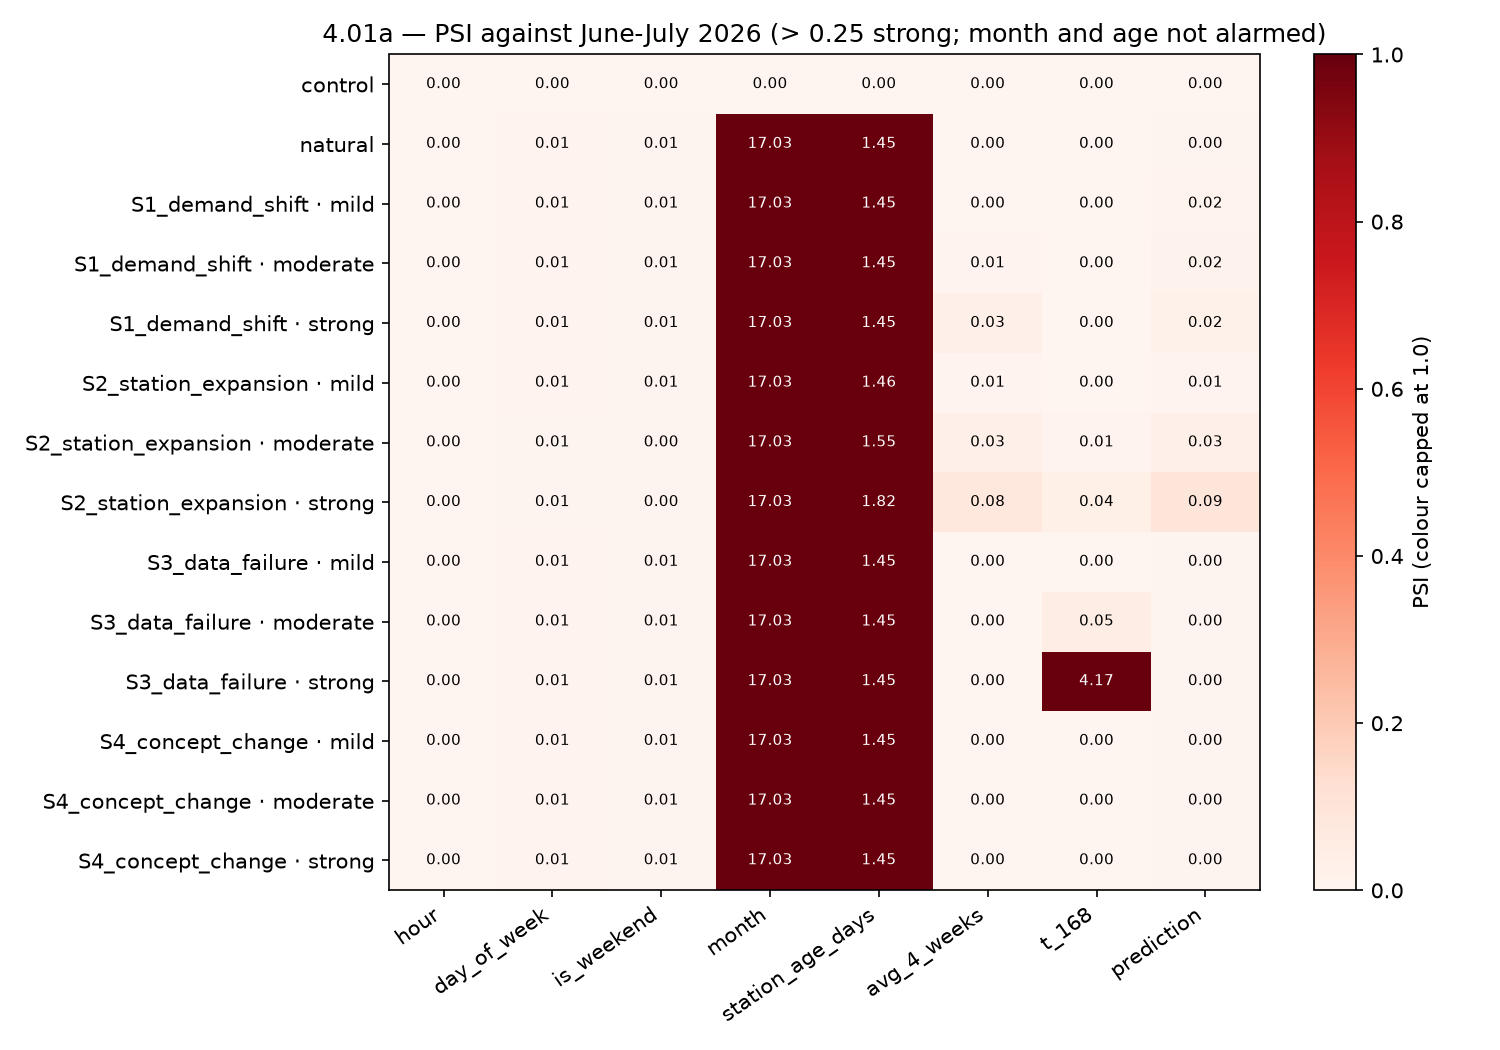

In [11]:
display(Image(EVIDENCE / "4.01a-psi-heatmap.png"))

In [12]:
alarmed = drift[drift["alarm"]]
wide = alarmed.pivot_table(index=["scenario", "level"], columns="feature", values="psi", sort=False)
ks = alarmed.pivot_table(index=["scenario", "level"], columns="feature", values="ks_d", sort=False)
print("PSI de las variables que cuentan para la alarma:")
display(wide[[f for f in FEATURES if f not in ALARM_EXCLUDED] + ["prediction"]].round(3))
print("KS D de las numéricas:")
ks[["avg_4_weeks", "t_168", "prediction"]].round(3)

PSI de las variables que cuentan para la alarma:


feature                        hour  day_of_week  is_weekend  avg_4_weeks  t_168  prediction
scenario             level                                                                  
control              none       0.0        0.000       0.000        0.000  0.000       0.000
natural              none       0.0        0.008       0.005        0.004  0.000       0.004
S1_demand_shift      mild       0.0        0.008       0.005        0.004  0.000       0.015
                     moderate   0.0        0.008       0.005        0.010  0.000       0.018
                     strong     0.0        0.008       0.005        0.031  0.000       0.024
S2_station_expansion mild       0.0        0.008       0.005        0.009  0.001       0.010
                     moderate   0.0        0.008       0.005        0.028  0.009       0.032
                     strong     0.0        0.007       0.005        0.084  0.036       0.093
S3_data_failure      mild       0.0        0.008       0.005        0.004  0.000       0.004
                     moderate   0.0        0.008       0.005        0.004  0.049       0.004
                     strong     0.0        0.008       0.005        0.004  4.166       0.004
S4_concept_change    mild       0.0        0.008       0.005        0.004  0.000       0.004
                     moderate   0.0        0.008       0.005        0.004  0.000       0.004
                     strong     0.0        0.008       0.005        0.004  0.000       0.004

KS D de las numéricas:


feature                        avg_4_weeks  t_168  prediction
scenario             level                                   
control              none            0.002  0.001       0.001
natural              none            0.028  0.013       0.029
S1_demand_shift      mild            0.075  0.186       0.058
                     moderate        0.075  0.187       0.058
                     strong          0.076  0.187       0.058
S2_station_expansion mild            0.044  0.026       0.048
                     moderate        0.079  0.051       0.087
                     strong          0.132  0.090       0.145
S3_data_failure      mild            0.028  0.013       0.029
                     moderate        0.028  0.124       0.029
                     strong          0.028  0.528       0.029
S4_concept_change    mild            0.028  0.013       0.029
                     moderate        0.028  0.013       0.029
                     strong          0.028  0.013       0.029

**Lo que muestra la tabla.** Solo **S3 strong** pasa el umbral de 0.25 (`t_168` con PSI 4.17). Ningún otro escenario lo pasa, ni siquiera los fuertes:

- **S1 strong** (+28 % de demanda): `avg_4_weeks` tiene PSI 0.031 y `t_168` 0.0002, aunque su KS D sube de 0.013 a **0.187**.
- **S2 strong:** la predicción tiene PSI 0.093, el mayor después de S3.
- **S4:** el PSI es idéntico al del periodo natural en los tres niveles. Así debe ser, porque S4 no toca las entradas.

¿Por qué el PSI casi no ve a S1? Porque las variables de historia son **conteos con muchos ceros**. En la referencia, 22 % de las filas tienen `avg_4_weeks = 0` y 47 % tienen `t_168 = 0`. Los cuantiles repiten el cero, los bins se fusionan, y `t_168` se queda con solo 4 bins en lugar de 10. Multiplicar por 1.28 mueve los valores **dentro** de cada bin ancho, y los ceros siguen en cero. El KS no usa bins, así que sí detecta el desplazamiento.

In [13]:
for feature in ["avg_4_weeks", "t_168"]:
    edges = quantile_edges(reference[feature])
    print(f"{feature}: {(reference[feature] == 0).mean():.0%} ceros · "
          f"{len(edges) - 1} bins · bordes internos {np.round(edges[1:-1], 2).tolist()}")

avg_4_weeks: 22% ceros · 8 bins · bordes internos [0.25, 0.5, 0.75, 1.0, 1.5, 2.25, 3.5]
t_168: 47% ceros · 4 bins · bordes internos [1.0, 2.0, 4.0]


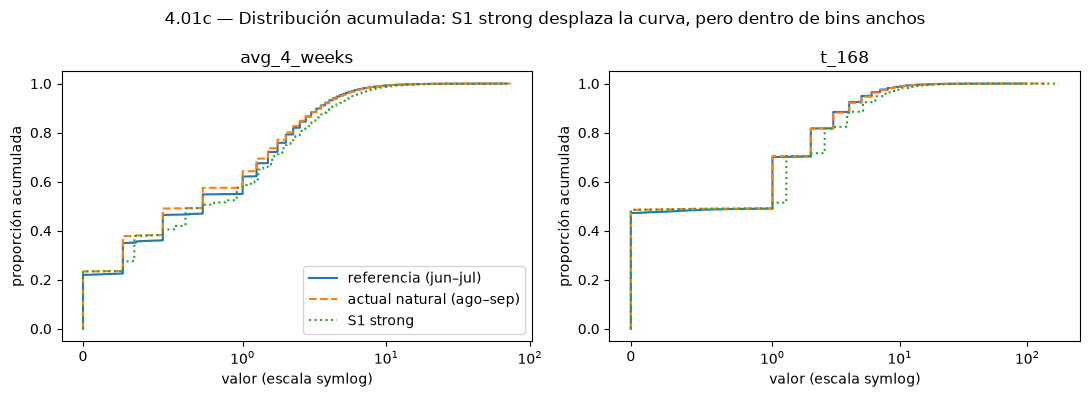

In [14]:
import matplotlib.pyplot as plt

s1_strong = sc.demand_shift(sc.history_window(df), recomputed["S1"]["strong"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, feature in zip(axes, ["avg_4_weeks", "t_168"]):
    for label, rows, style in [("referencia (jun–jul)", reference, "-"),
                               ("actual natural (ago–sep)", current, "--"),
                               ("S1 strong", s1_strong, ":")]:
        values = np.sort(rows[feature].to_numpy())
        ax.plot(values, np.arange(1, len(values) + 1) / len(values), style, label=label)
    ax.set_xscale("symlog", linthresh=1)
    ax.set_title(feature)
    ax.set_xlabel("valor (escala symlog)")
    ax.set_ylabel("proporción acumulada")
axes[0].legend()
fig.suptitle("4.01c — Distribución acumulada: S1 strong desplaza la curva, pero dentro de bins anchos")
fig.tight_layout()
fig.savefig(EVIDENCE / "4.01c-history-ecdf.png", dpi=150)
plt.show()

## 6. Desempeño del champion y del baseline

Cada escenario se evalúa con los **dos** modelos sobre las mismas filas. El baseline (`avg_4_weeks`) es la referencia de la regla de candidato de la Fase 2. Si el champion deja de superarlo, ya no hay razón para tenerlo en producción.

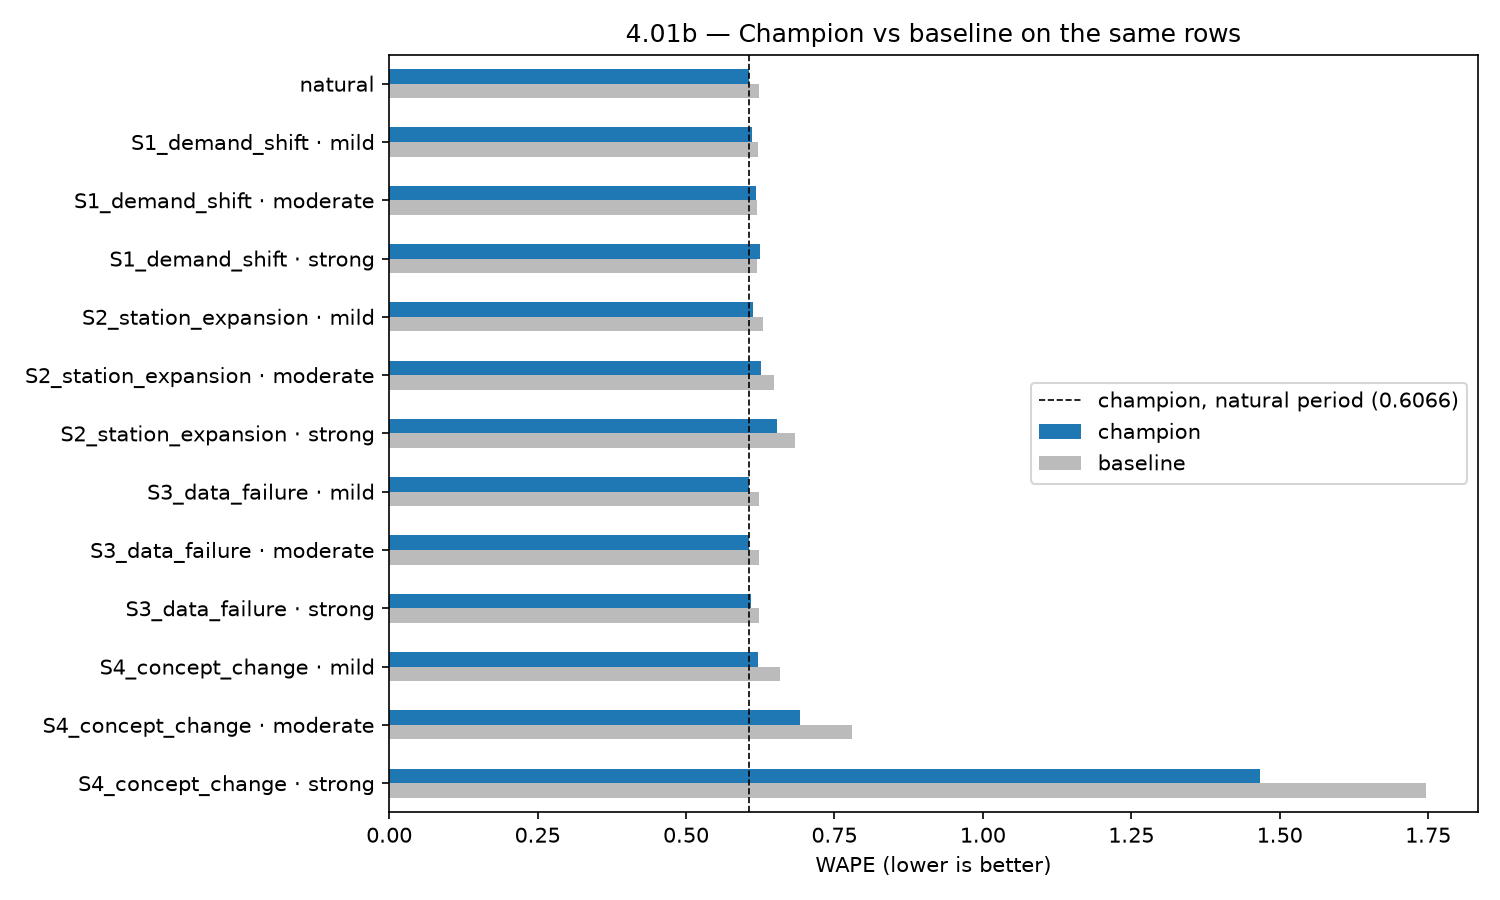

wape          volume_ratio                          wape
model                         champion baseline     champion baseline ventaja del champion
scenario             level                                                                
natural              none       0.6066   0.6227       0.7195   0.8956               0.0162
S1_demand_shift      mild       0.6114   0.6213       0.7879   0.8857               0.0100
                     moderate   0.6177   0.6193       0.7536   0.8668               0.0017
                     strong     0.6239   0.6187       0.7271   0.8424              -0.0052
S2_station_expansion mild       0.6125   0.6304       0.7154   0.8939               0.0180
                     moderate   0.6260   0.6478       0.7069   0.8906               0.0218
                     strong     0.6532   0.6829       0.6901   0.8844               0.0298
S3_data_failure      mild       0.6066   0.6227       0.7195   0.8956               0.0162
                     moderate   0.6069   0.6227       0.7182   0.8956               0.0159
                     strong     0.6093   0.6227       0.7115   0.8956               0.0134
S4_concept_change    mild       0.6210   0.6579       0.8456   1.0525               0.0369
                     moderate   0.6911   0.7788       1.0253   1.2762               0.0877
                     strong     1.4665   1.7459       1.7833   2.2198               0.2794

In [15]:
display(Image(EVIDENCE / "4.01b-wape-by-scenario.png"))
overall = performance[performance["segment"] == "all"]
table = overall.pivot_table(index=["scenario", "level"], columns="model",
                            values=["wape", "volume_ratio"], sort=False)
table[("wape", "ventaja del champion")] = table[("wape", "baseline")] - table[("wape", "champion")]
table.round(4)

**Lectura por escenario**

- **S1 · cambio de demanda.** El champion sí pierde desempeño: su WAPE sube de 0.6066 a 0.6114, 0.6177 y 0.6239 según el nivel. El baseline casi no cambia (0.619–0.621), porque su historia ya trae la demanda nueva desde la cuarta semana. En **S1 strong el champion deja de superar al baseline** (0.6239 contra 0.6187). La razón: HGB se entrenó con `absolute_error`, que pronostica la mediana, y no sigue el aumento de volumen tan rápido como el promedio de 4 semanas.
- **S2 · expansión.** Los dos modelos empeoran en el total (champion hasta 0.6532, baseline hasta 0.6829), pero el champion **conserva su ventaja**. La tabla por segmento (abajo) muestra que el WAPE **dentro** de cada segmento casi no cambia. La subida del total viene solo de la **mezcla**: hay más filas de la cohorte, que es el segmento más difícil (WAPE 0.85).
- **S3 · falla de `t_168`.** El champion casi no se entera: 0.6069 con 98 estaciones rotas y 0.6093 con todas. HGB depende sobre todo de `avg_4_weeks`, y el baseline no usa `t_168`. La falla es grave como dato, pero casi no cuesta desempeño.
- **S4 · cambio de concepto.** Es el único escenario que rompe a los dos modelos: champion 0.6210, 0.6911 y 1.4665, y baseline 0.6579, 0.7788 y 1.7459. El champion conserva su ventaja porque ya pronosticaba volumen de menos (`volume_ratio` 0.72). Al bajar la demanda, esa subestimación queda más cerca de la realidad.

In [16]:
s2 = performance[performance["scenario"].isin(["natural", "S2_station_expansion"])]
s2.pivot_table(index=["scenario", "level"], columns=["model", "segment"], values="wape",
               sort=False).round(4)

model                         champion                                         baseline                                        
segment                            all established_stations new_station_cohort      all established_stations new_station_cohort
scenario             level                                                                                                     
natural              none       0.6066               0.5866             0.8525   0.6227               0.5968             0.9409
S2_station_expansion mild       0.6125               0.5864             0.8531   0.6304               0.5966             0.9421
                     moderate   0.6260               0.5857             0.8558   0.6478               0.5957             0.9442
                     strong     0.6532               0.5864             0.8547   0.6829               0.5964             0.9440

## 7. Alertas y acción propuesta

Las cuatro reglas del contrato están en `mibici.monitoring.drift`:

| Señal | Umbral | Acción |
|---|---|---|
| Contrato de datos | Variable faltante, negativa o fuera de dominio (horas 0 y 5–23, `day_of_week` 0–6) | Revisar el pipeline de variables |
| Data drift | PSI > 0.25 en una variable con alarma o en la predicción | Investigar y confirmar con desempeño |
| Desempeño | WAPE del champion ≥ WAPE del baseline en las mismas filas | Reentrenar con datos recientes |
| Desempeño sin drift | El WAPE del champion sube más que la **tolerancia** frente al periodo natural, con todo PSI < 0.1 | Revisar las entradas del modelo (clima, eventos) |

**Tolerancia (ajuste propuesto al contrato).** El contrato dice "el WAPE sube", pero sin tolerancia cualquier subida mínima disparaba la regla. Por ejemplo, S3 moderate sube 0.0003, que es puro ruido. La tolerancia se calcula con los datos: se remuestrean con reemplazo los **días** del periodo natural 1,000 veces y se toma el percentil 97.5 del WAPE menos el WAPE observado. Da **0.0176**, así que una subida menor que esa se puede explicar por azar.

Si hay más de una alerta, la acción es la de la alerta más urgente. El orden es: dato roto, pérdida de la ventaja sobre el baseline, pérdida sin drift y drift solo.

In [17]:
cols = ["scenario", "level", "max_alarm_psi", "champion_wape", "baseline_wape",
        "data_contract_alert", "data_drift_alert", "performance_alert",
        "performance_without_drift_alert", "action", "expected_action", "matches_expected"]
print(f"Tolerancia del WAPE: {alerts['wape_tolerance'].dropna().iloc[0]:.4f}")
alerts[cols].round(4)

Tolerancia del WAPE: 0.0176


,scenario,level,max_alarm_psi,champion_wape,baseline_wape,data_contract_alert,data_drift_alert,performance_alert,performance_without_drift_alert,action,expected_action,matches_expected
0,control,none,0.0000,NaN,NaN,False,False,False,False,none,none,True
1,natural,none,0.0079,0.6066,0.6227,False,False,False,False,none,none,True
2,S1_demand_shift,mild,0.0151,0.6114,0.6213,False,False,False,False,none,retrain with recent data,False
3,S1_demand_shift,moderate,0.0182,0.6177,0.6193,False,False,False,False,none,retrain with recent data,False
4,S1_demand_shift,strong,0.0313,0.6239,0.6187,False,False,True,False,retrain with recent data,retrain with recent data,True
5,S2_station_expansion,mild,0.0105,0.6125,0.6304,False,False,False,False,none,retrain with recent data,False
6,S2_station_expansion,moderate,0.0325,0.6260,0.6478,False,False,False,True,"review the model inputs (add weather, events)",retrain with recent data,False
7,S2_station_expansion,strong,0.0927,0.6532,0.6829,False,False,False,True,"review the model inputs (add weather, events)",retrain with recent data,False
8,S3_data_failure,mild,0.0079,0.6066,0.6227,False,False,False,False,none,review the feature pipeline,False
9,S3_data_failure,moderate,0.0494,0.6069,0.6227,False,False,False,False,none,review the feature pipeline,False


**Resultado frente a lo esperado.** Los casos que coinciden con la acción esperada del contrato son: el control, el periodo natural, S1 strong (reentrenar) y S4 moderate y strong (revisar las entradas). Los casos que no coinciden son **hallazgos**, no fallas que haya que esconder:

1. **El contrato de datos no detecta S3.** Un `t_168 = 0` es un valor válido: no es negativo ni está fuera de dominio, y casi la mitad de las filas reales vale 0. Con todas las estaciones rotas lo detecta el data drift (PSI 4.17) y la acción es *investigar*. Con 1 o 98 estaciones no lo detecta nada. **Propuesta:** agregar al contrato de datos una regla por estación y día, por ejemplo `t_168 = 0` en todas las horas de una estación cuyo `avg_4_weeks > 0`.
2. **El PSI con bins por cuantiles es poco sensible en conteos con muchos ceros** (sección 5). S1 strong no levanta data drift, aunque KS D llega a 0.187. La alerta llega por desempeño, y solo cuando ya se observaron las salidas. **Propuesta:** agregar un umbral de KS D, o calcular el PSI con un bin propio para el cero y deciles de los valores positivos.
3. **S2 dispara "revisar las entradas" y no "reentrenar".** El champion no pierde contra el baseline, y el WAPE dentro de cada segmento no cambia. Lo que cambia es la mezcla de segmentos. La lectura correcta sale de la tabla por segmento, como pide el contrato: la cohorte nueva es donde el modelo es más débil (WAPE 0.85, volumen 0.57). Si la red sigue creciendo, eso es lo que hay que mejorar.
4. **Los niveles mild no levantan alertas** (S1, S2, S3 y S4). Sus cambios de WAPE (0.000–0.014) quedan dentro de la tolerancia de 0.0176. Que un cambio pequeño no dispare la alarma es lo que se espera de un monitoreo sin falsas alarmas.

## 8. Conclusiones

| Escenario | Data drift (PSI > 0.25) | Pérdida del champion | ¿Sigue superando al baseline? | Acción |
|---|---|---|---|---|
| Control / natural | No | — / referencia | Sí | Ninguna |
| S1 demanda (+4 %, +14 %, +28 %) | No (KS sí: 0.19) | +0.005 a +0.017 | No en strong | Reentrenar (strong) |
| S2 expansión (26 %, 36 %, 52 %) | No | +0.006 a +0.047 (por mezcla) | Sí | Revisar entradas (moderate, strong) |
| S3 falla de `t_168` | Solo strong (PSI 4.17) | ≤ +0.003 | Sí | Investigar (strong) |
| S4 concepto | No (entradas iguales) | +0.014 a +0.860 | Sí | Revisar entradas (moderate, strong) |

1. **El data drift y el performance drift sí son cosas distintas.** S4 pierde mucho desempeño sin ningún drift en las entradas. S3 strong tiene un drift enorme y casi no pierde desempeño. Monitorear solo uno de los dos deja huecos.
2. **El champion es robusto a fallas de `t_168` y a la expansión**, pero es **frágil ante aumentos de demanda**. Con un aumento como el de septiembre de 2026 (+28 %) deja de superar al baseline. Esto confirma la limitación de la Fase 2: HGB pronostica alrededor del 72 % del volumen.
3. **Dos ajustes propuestos al contrato:** excluir `station_age_days` de la alarma de drift y usar una tolerancia bootstrap en la regla de desempeño sin drift. **Dos mejoras propuestas:** una regla de datos por estación para detectar ceros sospechosos y un umbral de KS para las variables de historia.
4. **Lo que este análisis no cubre:** las perturbaciones son sintéticas y se aplican una a la vez. En producción pueden combinarse, por ejemplo un aumento de demanda junto con una expansión. Además, las alertas de desempeño solo existen cuando ya se observaron las salidas, es decir, con al menos un día de retraso.

**Reproducir:** `make drift`, o sin `make`: `python -m mibici.monitoring.evaluation`. Escribe todas las tablas y las figuras 4.01a y 4.01b. La figura 4.01c la genera esta libreta.

## Declaración de uso de IA

**Equipo:** 04 · **Actividad:** Entrega Final — 4.01 Data drift y performance drift
**Herramienta:** Claude Code (Anthropic) · **Modelo:** Claude Opus 5.5

**Uso declarado**
- Redacción del código de `mibici/monitoring/` (PSI, KS, escenarios, reglas de alerta y `make drift`) y de `tests/test_drift.py` a partir del contrato `docs/final/drift_contract.md`.
- Estructura de esta libreta, tablas de validación y figuras.

**Verificación y responsabilidad**
- Ejecución completa local ("Restart & Run All") en el ambiente `mibici` y `make drift` desde un commit limpio.
- Revisión de que la calibración de cada escenario sale de los datos reales y coincide con `calibration.csv`.
- Revisión y aprobación de los ajustes propuestos al contrato (exclusión de `station_age_days` y tolerancia bootstrap), de los hallazgos y de las conclusiones.